# Phase 3: Data Mining

**Dataset:** Preprocessed Student Performance Dataset (750 records, 23 columns)  
**Class label:** `final_grade` (A, B, C, D, F)

In this phase, we apply data mining techniques to the preprocessed Student Performance dataset from Phase 2. We use Decision Tree Classification to predict students' final grades using two attribute selection measures (Gini and Entropy) and three different data partitions (70/30, 80/20, and 90/10). We will also apply K-Means Clustering to group students based on similar characteristics. The results will be evaluated, compared, and visualized to understand the performance of each technique and identify useful patterns in the data.

# 1. Classification

## 1.1 Decision Tree Classification

In [15]:
import pandas as pd
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn import metrics
from sklearn.metrics import confusion_matrix
from sklearn import tree
import matplotlib.pyplot as plt

In [16]:
# Load the preprocessed student dataset
df = pd.read_csv("Preprocessed_dataset.csv")
print(df.head())

# Use final_grade as the target
y = df['final_grade']

# Remove the ID, target, and columns we do not need
X = df.drop(columns=[
    'student_id',
    'final_grade',
    'final_grade_transformed',
    'final_score',
    'gender',
    'internet_access',
    'parent_education',
    'part_time_job',
    'extracurricular'
])

# Convert the remaining categorical columns into numbers
X = pd.get_dummies(X)

fn = X.columns.tolist()

print("Features:", fn)
print("Dataset shape:", X.shape)

   student_id  age  gender  study_hours  attendance_rate  assignment_score  \
0           1   24  Female         3.06         0.248374          0.675286   
1           2   21    Male         3.26         0.133567          0.572774   
2           3   22  Female         4.63         0.418459          0.789989   
3           4   24  Female         3.42         0.790395          0.384559   
4           5   20    Male         2.15         0.582291          0.518471   

   midterm_score  final_score internet_access parent_education  ...  \
0       0.511979     0.728753              No              PhD  ...   
1       0.054015     0.750814             Yes      High School  ...   
2       0.543343     0.380367              No         Bachelor  ...   
3       0.760418     0.696328             Yes      High School  ...   
4       0.565558     0.620669             Yes           Master  ...   

   extracurricular final_grade  discretized_age discretized_study_hours  \
0              Yes           

In [17]:

# Try three different training and testing splits
partitions = {
    "70/30": 0.3,
    "80/20": 0.2,
    "90/10": 0.1
}

In [18]:

# Compare Gini and Entropy to see which one works better
criteria = ['gini', 'entropy']

results = []
result_matrices = []
best_accuracy = -1


In [19]:

# Train and test the Decision Tree using different splits
for partition, test_size in partitions.items():

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, random_state=1
    )

    # Try Gini and Entropy for each split
    for criterion in criteria:

        clf = DecisionTreeClassifier(
            criterion=criterion,
            random_state=1
        )

        clf = clf.fit(X_train, y_train)
        y_pred = clf.predict(X_test)

        # Check how well the model performs
        accuracy = metrics.accuracy_score(y_test, y_pred)

        train_accuracy = metrics.accuracy_score(
            y_train, clf.predict(X_train)
        )

        f1 = metrics.f1_score(
            y_test, y_pred,
            average='weighted',
            zero_division=0
        )

        cm = confusion_matrix(
            y_test, y_pred,
            labels=clf.classes_
        )

        print("\nPartition:", partition)
        print("Criterion:", criterion)
        print("Training Accuracy:", train_accuracy)
        print("Testing Accuracy:", accuracy)
        print("F1-score:", f1)
        print("Confusion Matrix:")
        print(cm)

        # Save the results to compare them later
        results.append({
            "Partition": partition,
            "Criterion": criterion,
            "Training Accuracy": train_accuracy,
            "Accuracy": accuracy,
            "F1-score": f1
        })

        # Save each confusion matrix for the plots
        result_matrices.append({
            "Partition": partition,
            "Criterion": criterion,
            "Matrix": cm,
            "Labels": clf.classes_
        })

        # Keep the model with the highest testing accuracy
        if accuracy > best_accuracy:
            best_accuracy = accuracy
            best_clf = clf
            best_partition = partition
            best_criterion = criterion



Partition: 70/30
Criterion: gini
Training Accuracy: 1.0
Testing Accuracy: 0.2088888888888889
F1-score: 0.20653677270543852
Confusion Matrix:
[[15  9  4 10 10]
 [13  4  7  8 12]
 [ 7  8 10  7  2]
 [11 13 10  8 11]
 [ 7 11  8 10 10]]

Partition: 70/30
Criterion: entropy
Training Accuracy: 1.0
Testing Accuracy: 0.24888888888888888
F1-score: 0.24168198584809636
Confusion Matrix:
[[ 8  7 14 10  9]
 [13 17  6  4  4]
 [ 6  8 13  5  2]
 [ 7 12 13 10 11]
 [11 11  7  9  8]]

Partition: 80/20
Criterion: gini
Training Accuracy: 1.0
Testing Accuracy: 0.2
F1-score: 0.20021340598060458
Confusion Matrix:
[[ 5  5  5  6  6]
 [ 6  4 11 11  1]
 [ 3  4  6  7  3]
 [ 7  6  8  8  5]
 [ 9  7  5  5  7]]

Partition: 80/20
Criterion: entropy
Training Accuracy: 1.0
Testing Accuracy: 0.26666666666666666
F1-score: 0.2702947670934154
Confusion Matrix:
[[ 6  2  6  6  7]
 [ 9  7  7  5  5]
 [ 4  4  5  5  5]
 [ 4  4  7 12  7]
 [10  5  5  3 10]]

Partition: 90/10
Criterion: gini
Training Accuracy: 1.0
Testing Accuracy: 0

In [20]:

# Put all six results in one table
results_df = pd.DataFrame(results)

print("Comparison Results:")
print(results_df.to_string(index=False))

# Show the best result from our experiments
print("\nBest Partition:", best_partition)
print("Best Criterion:", best_criterion)
print("Best Accuracy:", best_accuracy)


Comparison Results:
Partition Criterion  Training Accuracy  Accuracy  F1-score
    70/30      gini                1.0  0.208889  0.206537
    70/30   entropy                1.0  0.248889  0.241682
    80/20      gini                1.0  0.200000  0.200213
    80/20   entropy                1.0  0.266667  0.270295
    90/10      gini                1.0  0.173333  0.167267
    90/10   entropy                1.0  0.253333  0.253775

Best Partition: 80/20
Best Criterion: entropy
Best Accuracy: 0.26666666666666666


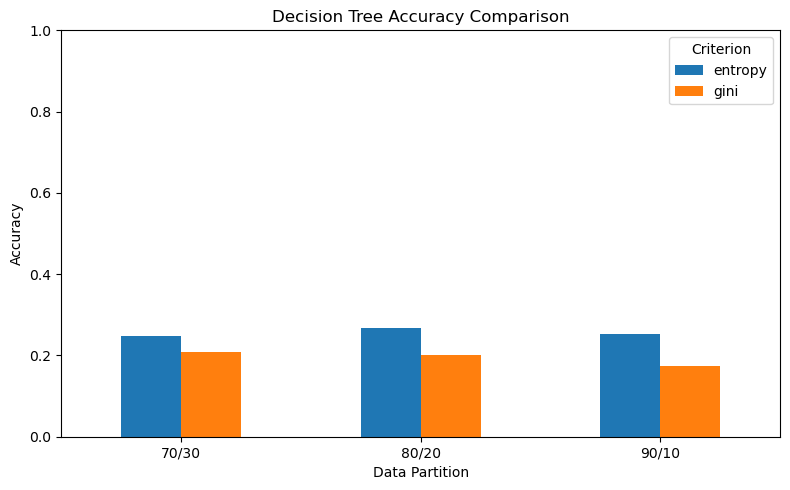

In [21]:

# Compare the accuracy of Gini and Entropy
accuracy_table = results_df.pivot(
    index="Partition",
    columns="Criterion",
    values="Accuracy"
)

accuracy_table = accuracy_table.reindex(
    ["70/30", "80/20", "90/10"]
)

accuracy_table.plot(kind="bar", figsize=(8, 5))

plt.title("Decision Tree Accuracy Comparison")
plt.xlabel("Data Partition")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(title="Criterion")
plt.tight_layout()
plt.show()


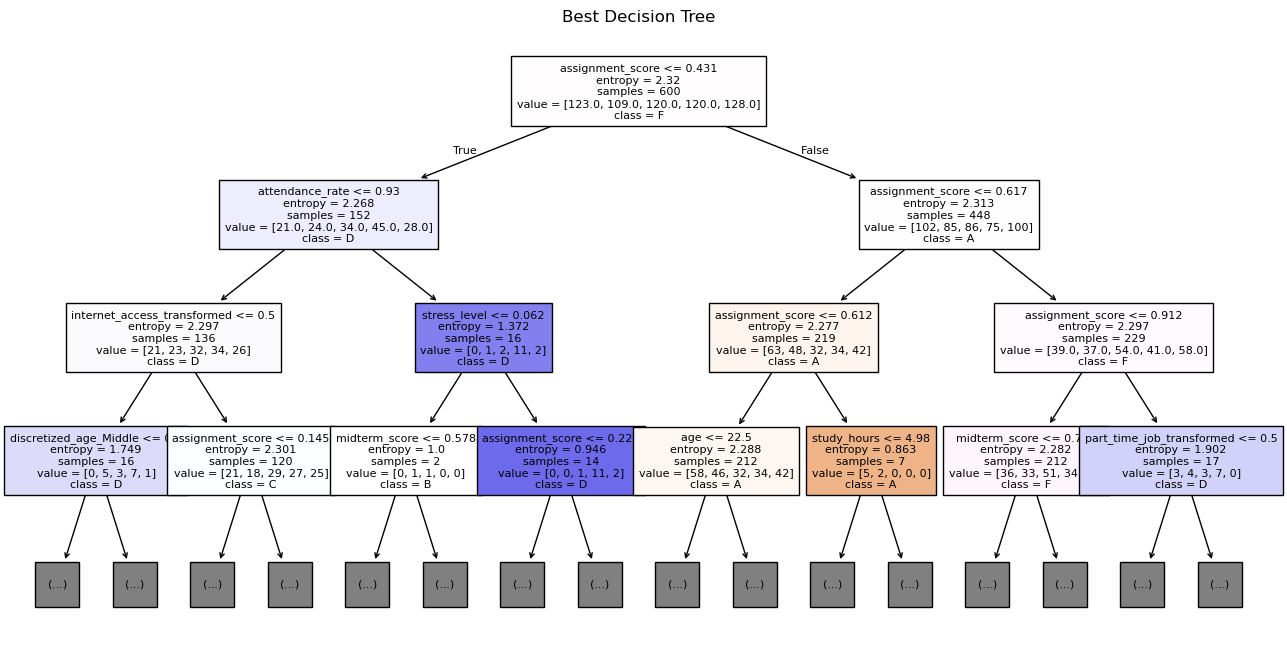

In [22]:

# Draw the tree to see how the model makes its decisions
plt.figure(figsize=(16, 8))

tree.plot_tree(
    best_clf,
    feature_names=fn,
    class_names=[str(c) for c in best_clf.classes_],
    filled=True,
    max_depth=3,
    fontsize=8
)

plt.title("Best Decision Tree")
plt.show()


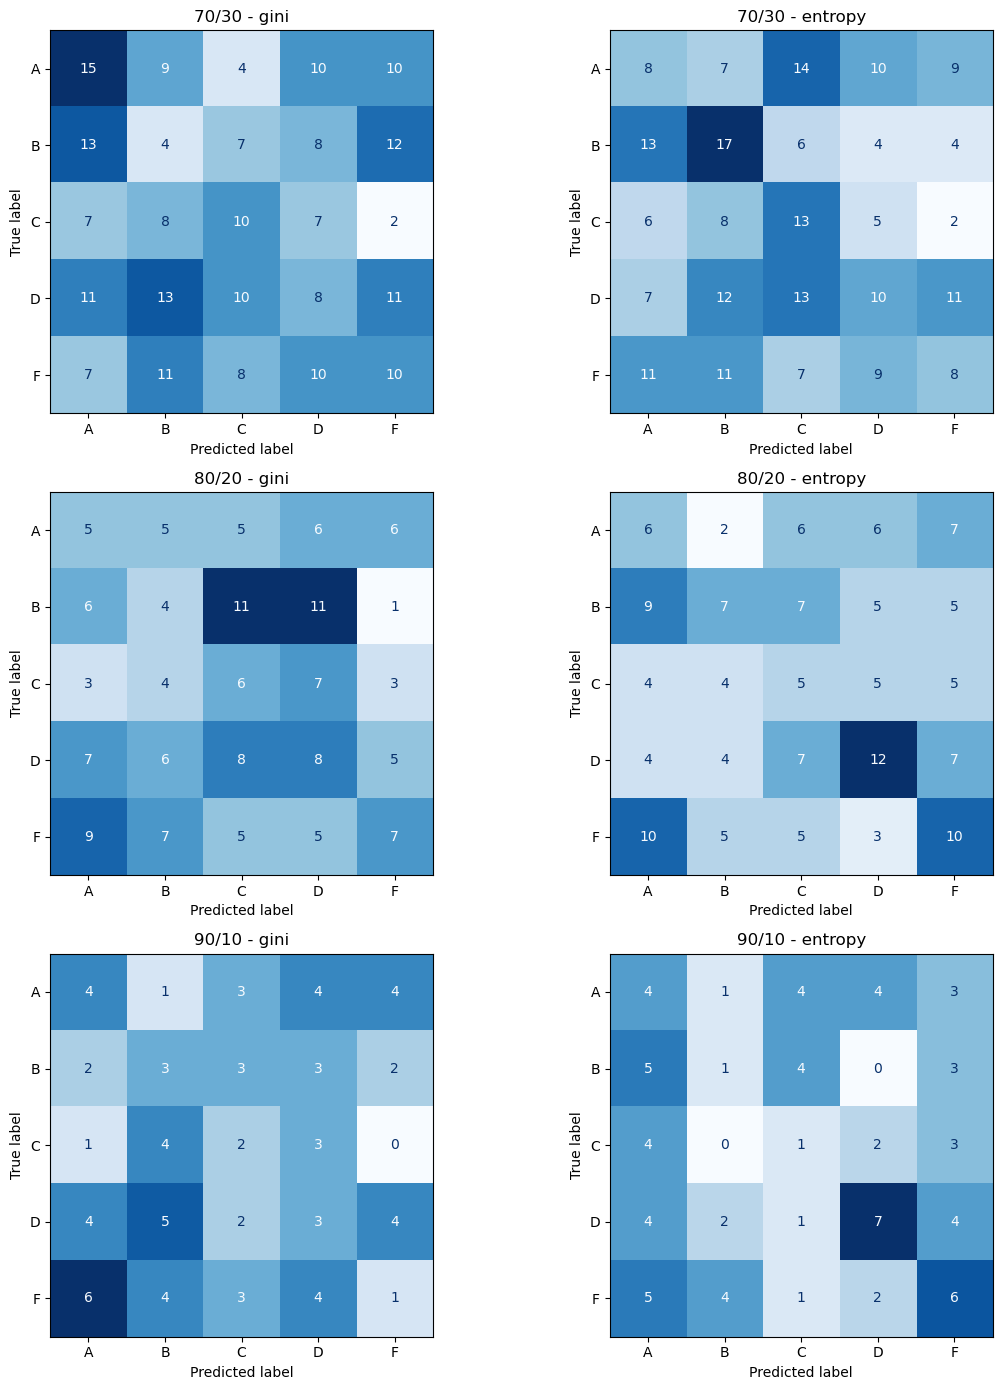

In [23]:

# Show the confusion matrix for all six experiments
fig, axes = plt.subplots(3, 2, figsize=(12, 14))

for ax, result in zip(axes.flat, result_matrices):

    disp = metrics.ConfusionMatrixDisplay(
        confusion_matrix=result["Matrix"],
        display_labels=result["Labels"]
    )

    disp.plot(
        ax=ax,
        cmap="Blues",
        colorbar=False
    )

    ax.set_title(
        result["Partition"] + " - " + result["Criterion"]
    )

plt.tight_layout()
plt.show()


**Description:** The table compares the performance of Decision Tree Classification using Gini and Entropy with three different data partitions (70/30, 80/20, and 90/10).

**What it tells us:** The results show differences in accuracy between Gini and Entropy across the three partitions. The training accuracy is also compared with the testing accuracy to check for overfitting.

**Conclusion:** The best-performing configuration is identified based on testing accuracy. However, the difference between training and testing accuracy should also be considered when evaluating the model.